# 10. Random Forest: Regression vs Classification and Feature Importance

CSCI323 Modern AI — Group FT13 (owner: Jiachen)

This notebook supplements `Red_White_Wine_Quality_Modelling_Comparisons.ipynb`. It uses **the same data cleaning and the same 80/20 stratified split (random_state = 42)**, so the results are directly comparable with the main notebook.

**Questions investigated**
1. Wine quality is an integer score. Is it better to model it as a continuous target (regression) or as discrete classes (classification)?
2. Where does each approach fail, especially for rare quality scores (marginal cases)?
3. Which features matter most for the tuned Random Forest, for red and white wine?

**Method**
- `RandomForestRegressor` and `RandomForestClassifier` are tuned with the same grid as Section 8.2 (tree count, maximum depth, minimum leaf size) and the same criterion (five-fold CV MAE on the training set only).
- Both are evaluated once on the test set with MAE, RMSE, exact accuracy and within ±1 accuracy (regression predictions rounded for the accuracy metrics).
- Errors are broken down by true quality score.
- Permutation importance (20 repeats, test MAE) is computed for the tuned regressor.

## 10.1 Load, clean and split the data (same as Sections 1–2)

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

base_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"
df = pd.read_csv(base_url + "winequality-red.csv", sep=";")
white_df = pd.read_csv(base_url + "winequality-white.csv", sep=";")

# Remove exact duplicate rows before splitting
df_clean = df.drop_duplicates().copy()
white_df_clean = white_df.drop_duplicates().copy()

X = df_clean.drop(columns=["quality"]); y = df_clean["quality"]
white_X = white_df_clean.drop(columns=["quality"]); white_y = white_df_clean["quality"]

# Same 80/20 stratified split as the main notebook
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
white_X_train, white_X_test, white_y_train, white_y_test = train_test_split(
    white_X, white_y, test_size=0.2, random_state=42, stratify=white_y)

print("Red:   train", X_train.shape, "| test", X_test.shape)
print("White: train", white_X_train.shape, "| test", white_X_test.shape)

Red:   train (1087, 11) | test (272, 11)
White: train (3168, 11) | test (793, 11)


## 10.2 Regression vs classification, error by quality score and feature importance

Note: for white wine, scikit-learn may warn that quality 9 has fewer than 5 training samples, so StratifiedKFold cannot place it in every fold. This does not affect the results.


==================== Red wine ====================
Best regressor params:  {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200} | CV MAE 0.4905
Best classifier params: {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200} | CV MAE 0.4415

Red wine: test results


,Approach,MAE,RMSE,Exact accuracy,Within ±1 accuracy
0,RF Regression,0.4846,0.6316,0.6029,0.9743
1,RF Classification,0.4338,0.7174,0.6029,0.9669



Red wine: test MAE by quality score


,Samples,Regression_MAE,Classification_MAE
Quality,,,
3,2,2.078,2.500
4,11,1.030,1.273
5,116,0.372,0.267
6,107,0.422,0.374
7,33,0.723,0.727
8,3,1.366,1.333


Scores predicted by the classifier: {5: np.int64(128), 6: np.int64(121), 7: np.int64(23)}
Range of regression predictions: 4.47 to 7.06

Red wine: feature importance (tuned RF regressor)


,Feature,Impurity importance,Permutation importance (MAE increase),Permutation std
0,alcohol,0.2939,0.1222,0.0142
1,sulphates,0.1577,0.0626,0.0103
2,volatile acidity,0.1484,0.0339,0.0080
3,total sulfur dioxide,0.0695,0.0214,0.0047
4,density,0.0460,0.0066,0.0016
5,free sulfur dioxide,0.0436,0.0062,0.0028
6,citric acid,0.0466,0.0053,0.0027
7,pH,0.0500,0.0051,0.0025
8,residual sugar,0.0445,0.0028,0.0023
9,chlorides,0.0580,0.0023,0.0023


... (4 outputs left out)


White wine: test MAE by quality score


,Samples,Regression_MAE,Classification_MAE
Quality,,,
3,4,2.601,2.750
4,31,1.118,1.226
5,235,0.528,0.409
6,358,0.353,0.260
7,138,0.663,0.732
8,26,1.578,1.615
9,1,2.021,2.000


Scores predicted by the classifier: {4: np.int64(7), 5: np.int64(230), 6: np.int64(473), 7: np.int64(81), 8: np.int64(2)}
Range of regression predictions: 4.17 to 7.29

White wine: feature importance (tuned RF regressor)


,Feature,Impurity importance,Permutation importance (MAE increase),Permutation std
0,alcohol,0.2874,0.1572,0.0153
1,volatile acidity,0.1189,0.0530,0.0080
2,free sulfur dioxide,0.1228,0.0397,0.0070
3,chlorides,0.0524,0.0146,0.0027
4,pH,0.0735,0.0126,0.0040
5,residual sugar,0.0600,0.0121,0.0024
6,total sulfur dioxide,0.0643,0.0106,0.0025
7,citric acid,0.0542,0.0083,0.0022
8,fixed acidity,0.0549,0.0080,0.0023
9,sulphates,0.0605,0.0053,0.0020


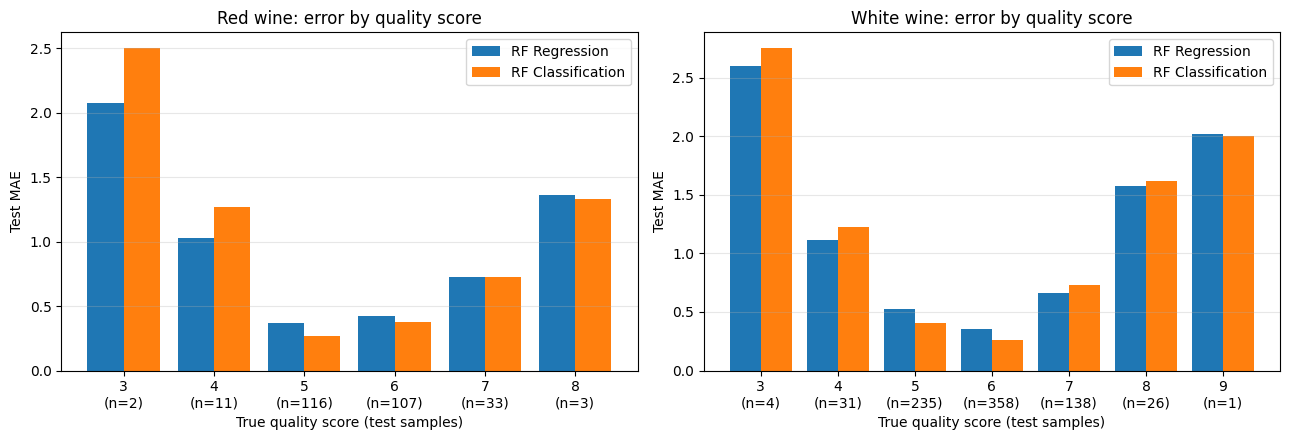

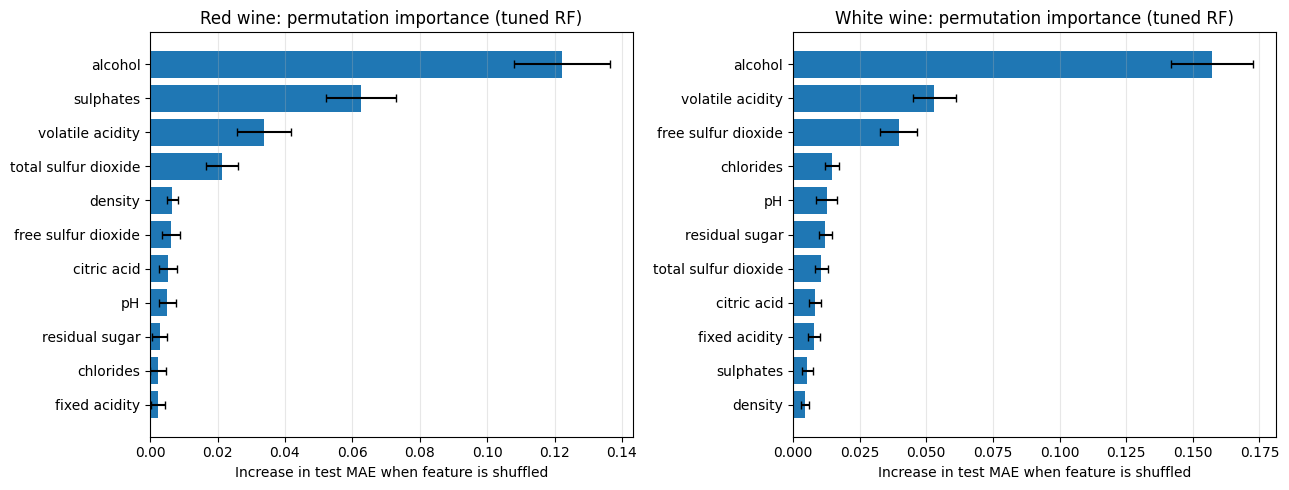

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score
from sklearn.inspection import permutation_importance

# Same Random Forest grid as Le's tuning (Section 8)
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 3, 5],
}


def tune_rf_regressor(X_tr, y_tr):
    """Tune RandomForestRegressor with 5-fold CV on the training set only."""
    grid = GridSearchCV(
        RandomForestRegressor(random_state=42, n_jobs=1),
        param_grid,
        scoring="neg_mean_absolute_error",
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        n_jobs=-1,
    )
    grid.fit(X_tr, y_tr)
    return grid


def tune_rf_classifier(X_tr, y_tr):
    """Tune RandomForestClassifier with the SAME grid and the SAME metric (MAE),
    so the comparison with the regressor is fair.
    StratifiedKFold keeps the rare scores in every fold."""
    grid = GridSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=1),
        param_grid,
        scoring="neg_mean_absolute_error",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        n_jobs=-1,
    )
    grid.fit(X_tr, y_tr)
    return grid


def evaluate(y_true, y_pred, name):
    """Same metrics for both approaches.
    Regressor predictions are rounded to whole scores for the accuracy metrics."""
    y_round = np.clip(np.rint(y_pred), y_true.min(), y_true.max())
    return {
        "Approach": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Exact accuracy": accuracy_score(y_true, y_round),
        "Within ±1 accuracy": np.mean(np.abs(y_round - y_true) <= 1),
    }


def mae_by_score(y_true, pred_reg, pred_clf):
    """Error for each quality score separately (marginal-case analysis)."""
    df = pd.DataFrame({"Quality": y_true.values,
                       "Regression": np.abs(pred_reg - y_true.values),
                       "Classification": np.abs(pred_clf - y_true.values)})
    out = df.groupby("Quality").agg(
        Samples=("Regression", "size"),
        Regression_MAE=("Regression", "mean"),
        Classification_MAE=("Classification", "mean"),
    )
    return out


def run_experiment(X_tr, X_te, y_tr, y_te, wine):
    print(f"\n==================== {wine} wine ====================")

    # 1) Tune both models on the training set only
    reg_grid = tune_rf_regressor(X_tr, y_tr)
    clf_grid = tune_rf_classifier(X_tr, y_tr)
    print("Best regressor params: ", reg_grid.best_params_,
          f"| CV MAE {-reg_grid.best_score_:.4f}")
    print("Best classifier params:", clf_grid.best_params_,
          f"| CV MAE {-clf_grid.best_score_:.4f}")

    rf_reg = reg_grid.best_estimator_
    rf_clf = clf_grid.best_estimator_

    # 2) Evaluate once on the test set
    pred_reg = rf_reg.predict(X_te)
    pred_clf = rf_clf.predict(X_te)

    results = pd.DataFrame([
        evaluate(y_te, pred_reg, "RF Regression"),
        evaluate(y_te, pred_clf, "RF Classification"),
    ])
    print(f"\n{wine} wine: test results")
    display(results.round(4))

    # 3) Error by quality score (where does each approach fail?)
    by_score = mae_by_score(y_te, pred_reg, pred_clf)
    print(f"\n{wine} wine: test MAE by quality score")
    display(by_score.round(3))

    # Which scores does each approach actually predict?
    print("Scores predicted by the classifier:",
          dict(pd.Series(pred_clf).value_counts().sort_index()))
    print("Range of regression predictions:",
          f"{pred_reg.min():.2f} to {pred_reg.max():.2f}")

    # 4) Feature importance of the TUNED regressor
    perm = permutation_importance(
        rf_reg, X_te, y_te,
        scoring="neg_mean_absolute_error",
        n_repeats=20, random_state=42, n_jobs=-1,
    )
    importance = pd.DataFrame({
        "Feature": X_tr.columns,
        "Impurity importance": rf_reg.feature_importances_,
        "Permutation importance (MAE increase)": perm.importances_mean,
        "Permutation std": perm.importances_std,
    }).sort_values("Permutation importance (MAE increase)", ascending=False)
    print(f"\n{wine} wine: feature importance (tuned RF regressor)")
    display(importance.round(4).reset_index(drop=True))

    return results, by_score, importance


red_results, red_by_score, red_importance = run_experiment(
    X_train, X_test, y_train, y_test, "Red")
white_results, white_by_score, white_importance = run_experiment(
    white_X_train, white_X_test, white_y_train, white_y_test, "White")


# ---------------- Figures for the report / slides ----------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (wine, by_score) in zip(axes, [("Red", red_by_score), ("White", white_by_score)]):
    x = np.arange(len(by_score))
    ax.bar(x - 0.2, by_score["Regression_MAE"], 0.4, label="RF Regression")
    ax.bar(x + 0.2, by_score["Classification_MAE"], 0.4, label="RF Classification")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{q}\n(n={n})" for q, n in zip(by_score.index, by_score["Samples"])])
    ax.set_xlabel("True quality score (test samples)")
    ax.set_ylabel("Test MAE")
    ax.set_title(f"{wine} wine: error by quality score")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("rf_reg_vs_clf_by_score.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (wine, imp) in zip(axes, [("Red", red_importance), ("White", white_importance)]):
    imp_sorted = imp.sort_values("Permutation importance (MAE increase)")
    ax.barh(imp_sorted["Feature"], imp_sorted["Permutation importance (MAE increase)"],
            xerr=imp_sorted["Permutation std"], capsize=3)
    ax.set_title(f"{wine} wine: permutation importance (tuned RF)")
    ax.set_xlabel("Increase in test MAE when feature is shuffled")
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("rf_feature_importance_red_white.png", dpi=300, bbox_inches="tight")
plt.show()

## 10.3 Summary of Findings

- **Overall results.** Classification gave a lower test MAE than regression (red 0.434 vs 0.485; white 0.483 vs 0.543) but a higher RMSE (red 0.717 vs 0.632; white 0.776 vs 0.698). Exact accuracy was almost identical (red 60.3% for both; white 57.3% vs 57.5%).
- **Why.** Squared-error regression predicts the conditional mean E[Y | X], so predictions are pulled towards the centre of the scale (red predictions only ranged from 4.47 to 7.06). A classifier predicts the most probable class; because scores 5 and 6 dominate, it is more often exactly right for common wines but makes larger mistakes when it is wrong.
- **Marginal cases.** On red wine the classifier predicted only scores 5–7 and never 3, 4 or 8. For red wines scored 3 or 4, MAE was above 1.0 for both approaches and higher for classification. Changing the target type shifts the errors rather than removing them, so rare scores need imbalance handling (weighting / oversampling).
- **Feature importance.** Alcohol is the most important feature for both wines (test MAE increase 0.12 red, 0.16 white). Next are sulphates and volatile acidity for red, and volatile acidity and free sulphur dioxide for white, so the two wine types depend on different chemical properties.